# Analisis Pengaruh Kuantisasi terhadap Explainable AI (XAI)
### Studi Kasus: Fine-tuning Qwen2.5-0.5B untuk Klasifikasi Toksisitas pada IndoToxic2024

**Rumusan masalah**: apakah kuantisasi post-training (PTQ Dynamic & PTQ Static, INT8) pada model bahasa
yang telah di-fine-tune mempengaruhi (1) performa klasifikasi, dan (2) konsistensi interpretasi SHAP
dibanding model asal (FP32)?

**Alur eksperimen** (lihat `README.md` untuk detail lengkap):

| Tahap | Dikerjakan oleh |
|---|---|
| Preprocessing & split data | `src/data_utils.py` (dipanggil `src/train.py`) |
| Fine-tuning Qwen2.5-0.5B (FP32) | `src/train.py` |
| Export ke ONNX | `src/export_onnx.py` |
| Kuantisasi PTQ Dynamic & Static | `src/quantize.py` |
| Interpretasi SHAP + metrik kemiripan | `src/shap_analysis.py` |

**Notebook ini tidak menjalankan satupun proses di atas.** Semua proses berat dijalankan lewat
terminal dan hasilnya (model, ONNX, metrik, SHAP) disimpan sebagai *artifact* di folder `artifacts/`
(terpisah dari notebook). Notebook ini murni **membaca artifact tersebut** untuk evaluasi, analisis,
visualisasi, dan perbandingan — sehingga ringan, cepat dibuka, dan tidak berisiko crash.


In [15]:
import sys, json, pickle
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Cari folder src/ (robust terhadap working directory: repo root ATAU notebooks/)
def _find_src_dir(start: Path) -> Path:
    for parent in [start] + list(start.parents):
        candidate = parent / "src"
        if (candidate / "config.py").exists():
            return candidate
    raise FileNotFoundError("Folder 'src' tidak ditemukan. Buka notebook ini dari dalam repo.")

SRC_DIR = _find_src_dir(Path.cwd())
sys.path.insert(0, str(SRC_DIR))

import config as cfg
import onnx_utils as ou

print("Repo root:", cfg.REPO_ROOT)


Repo root: /home/ibay/Documents/tugas akhir/qwen-indodiscourse-quant-xai-final/qwen-indodiscourse-quant-xai


## 1. Dataset & Preprocessing

Train: 21286 | Val: 2661 | Test: 2661


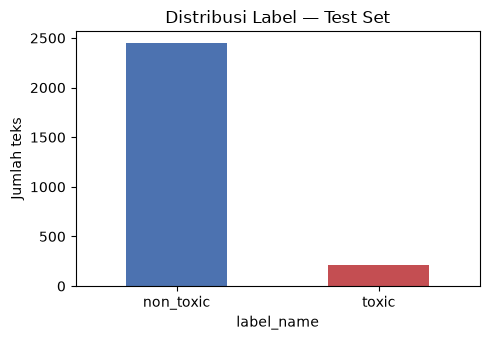

In [16]:
assert cfg.TEST_CSV.exists(), (
    f"'{cfg.TEST_CSV}' belum ada. Jalankan 'python train.py' dulu (lihat README.md)."
)

train_df = pd.read_csv(cfg.TRAIN_CSV)
val_df = pd.read_csv(cfg.VAL_CSV)
test_df = pd.read_csv(cfg.TEST_CSV)

print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

fig, ax = plt.subplots(figsize=(5, 3.5))
test_df["label_name"].value_counts().plot(kind="bar", color=["#4C72B0", "#C44E52"], ax=ax)
ax.set_title("Distribusi Label — Test Set")
ax.set_ylabel("Jumlah teks")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Label diagregasi lewat *strict majority vote* dari beberapa annotator per teks (kolom `toxicity`);
teks dengan suara seri dibuang. Dataset ini timpang (~92% non-toxic vs ~8% toxic) — perlu diperhatikan
saat membaca metrik: F1/precision/recall kelas *toxic* lebih informatif daripada accuracy mentah.


## 2. Fine-tuning Model FP32

In [17]:
assert cfg.FP32_PYTORCH_METRICS_JSON.exists(), (
    f"'{cfg.FP32_PYTORCH_METRICS_JSON}' belum ada. Jalankan 'python train.py' dulu."
)

with open(cfg.FP32_PYTORCH_METRICS_JSON) as f:
    train_metrics = json.load(f)

rows = []
for split in ["val", "test"]:
    row = {"split": split}
    for m in ["accuracy", "precision", "recall", "f1", "loss"]:
        key = f"{split}_{m}"
        if key in train_metrics:
            row[m] = train_metrics[key]
    rows.append(row)

pd.DataFrame(rows).round(4)


,split,accuracy,precision,recall,f1,loss
0,val,0.9102,0.4362,0.3814,0.4069,0.2578
1,test,0.9094,0.4365,0.3981,0.4165,0.2604


## 3. Export ONNX & Kuantisasi — FP32 vs Dynamic INT8 vs Static INT8

In [18]:
assert cfg.RESULTS_JSON.exists(), (
    f"'{cfg.RESULTS_JSON}' belum ada. Jalankan 'python export_onnx.py' lalu 'python quantize.py' dulu."
)

with open(cfg.RESULTS_JSON) as f:
    results = json.load(f)

results_df = pd.DataFrame(results).T.reset_index().rename(columns={"index": "Model"})
fp32_row = results_df.loc[results_df["Model"] == "FP32"].iloc[0]
results_df["size_reduction_%"] = (1 - results_df["size_mb"] / fp32_row["size_mb"]) * 100
for m in ["accuracy", "precision", "recall", "f1"]:
    results_df[f"delta_{m}"] = results_df[m] - fp32_row[m]

results_df.round(4)


,Model,size_mb,accuracy,precision,recall,f1,size_reduction_%,delta_accuracy,delta_precision,delta_recall,delta_f1
0,FP32,1889.1018,0.9094,0.4365,0.3981,0.4165,0.0000,0.0000,0.0000,0.0000,0.0000
1,Dynamic_INT8,475.4690,0.9158,0.4545,0.1852,0.2632,74.8309,0.0064,0.0180,-0.2130,-0.1533
2,Static_INT8,476.1911,0.8910,0.0488,0.0185,0.0268,74.7927,-0.0184,-0.3878,-0.3796,-0.3896


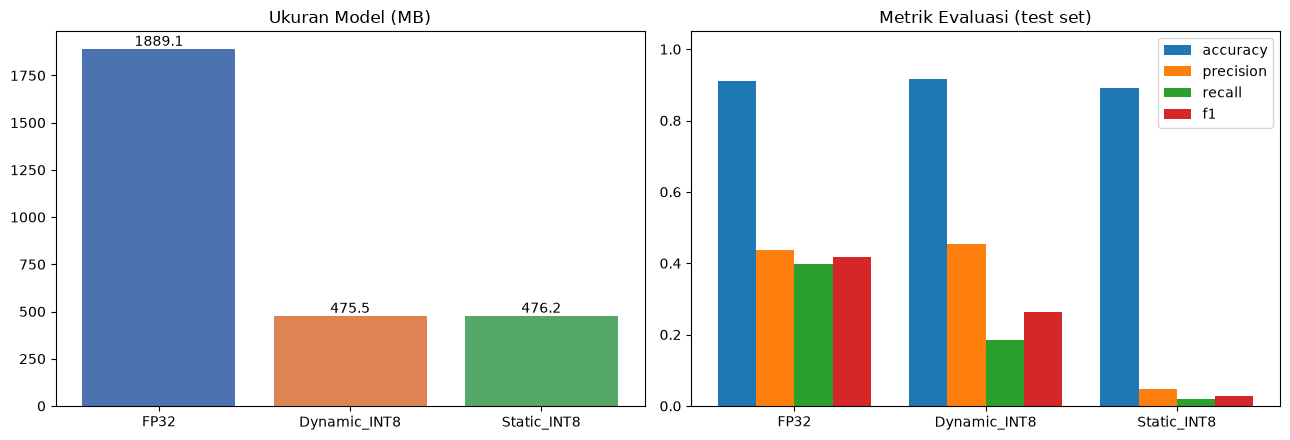

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

colors = ["#4C72B0", "#DD8452", "#55A868"]
axes[0].bar(results_df["Model"], results_df["size_mb"], color=colors[:len(results_df)])
axes[0].set_title("Ukuran Model (MB)")
for i, v in enumerate(results_df["size_mb"]):
    axes[0].text(i, v, f"{v:.1f}", ha="center", va="bottom")

x = np.arange(len(results_df))
for j, m in enumerate(["accuracy", "precision", "recall", "f1"]):
    axes[1].bar(x + j * 0.2, results_df[m], width=0.2, label=m)
axes[1].set_xticks(x + 0.3)
axes[1].set_xticklabels(results_df["Model"])
axes[1].set_ylim(0, 1.05)
axes[1].set_title("Metrik Evaluasi (test set)")
axes[1].legend()

plt.tight_layout()
plt.show()


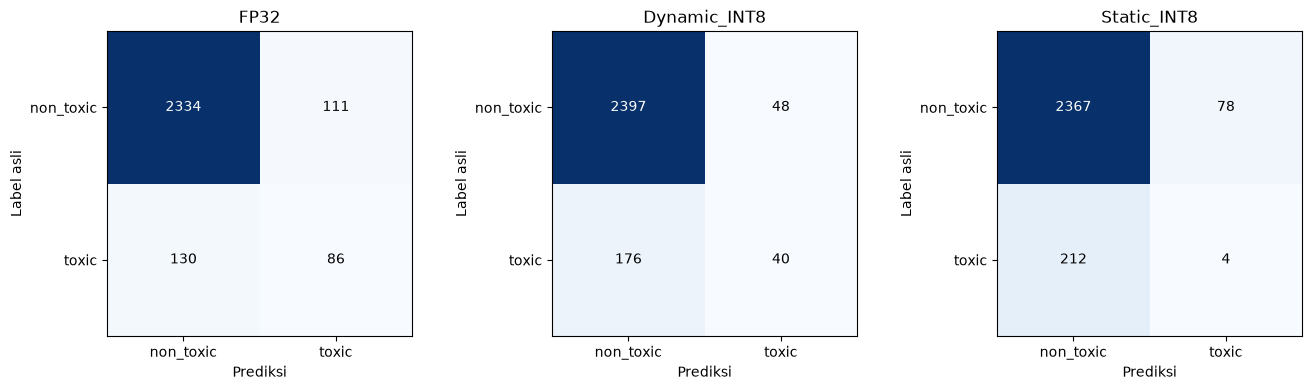

In [20]:
preds_df = pd.read_csv(cfg.PREDICTIONS_CSV)
model_cols = {"FP32": "fp32_pred", "Dynamic_INT8": "dynamic_pred", "Static_INT8": "static_pred"}
model_cols = {k: v for k, v in model_cols.items() if v in preds_df.columns}

fig, axes = plt.subplots(1, len(model_cols), figsize=(4.5 * len(model_cols), 4))
if len(model_cols) == 1:
    axes = [axes]

for ax, (name, col) in zip(axes, model_cols.items()):
    cm = confusion_matrix(preds_df["label"], preds_df[col])
    ax.imshow(cm, cmap="Blues")
    ax.set_title(name)
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(cfg.LABEL_NAMES.values()); ax.set_yticklabels(cfg.LABEL_NAMES.values())
    ax.set_xlabel("Prediksi"); ax.set_ylabel("Label asli")
    for r in range(2):
        for c in range(2):
            ax.text(c, r, cm[r, c], ha="center", va="center",
                     color="white" if cm[r, c] > cm.max() / 2 else "black")
plt.tight_layout()
plt.show()


## 4. Latensi & Throughput Inferensi

Selain akurasi dan ukuran model, **kecepatan inferensi** adalah salah satu motivasi utama
kuantisasi — model yang lebih kecil semestinya lebih cepat dijalankan. Diukur oleh
`benchmark_latency.py` pada CPU yang sama untuk ketiga model: rata-rata, standar deviasi, dan
persentil p95/p99 dari 100 kali run (setelah 10 run warm-up dibuang untuk menghindari bias
cold-start), pada batch size 1 (skenario request tunggal/interaktif) dan batch size lebih besar
(throughput saat diproses berkelompok).


In [21]:
assert cfg.LATENCY_JSON.exists(), (
    f"'{cfg.LATENCY_JSON}' belum ada. Jalankan 'python benchmark_latency.py' dulu."
)

with open(cfg.LATENCY_JSON) as f:
    latency = json.load(f)

rows = []
for model_name, batches in latency.items():
    for batch_key, m in batches.items():
        rows.append({
            "Model": model_name,
            "batch_size": m["batch_size"],
            "mean_ms": m["mean_ms"],
            "p95_ms": m["p95_ms"],
            "p99_ms": m["p99_ms"],
            "throughput_samples_per_sec": m["throughput_samples_per_sec"],
        })

latency_df = pd.DataFrame(rows).round(3)
latency_df


,Model,batch_size,mean_ms,p95_ms,p99_ms,throughput_samples_per_sec
0,FP32,1,44.250,47.500,47.804,22.599
1,FP32,8,3376.319,3389.677,3390.244,2.369
2,Dynamic_INT8,1,20.644,21.705,22.451,48.441
3,Dynamic_INT8,8,1796.865,1804.509,1808.931,4.452
4,Static_INT8,1,129.887,135.567,137.929,7.699
5,Static_INT8,8,4066.329,4086.338,4223.463,1.967


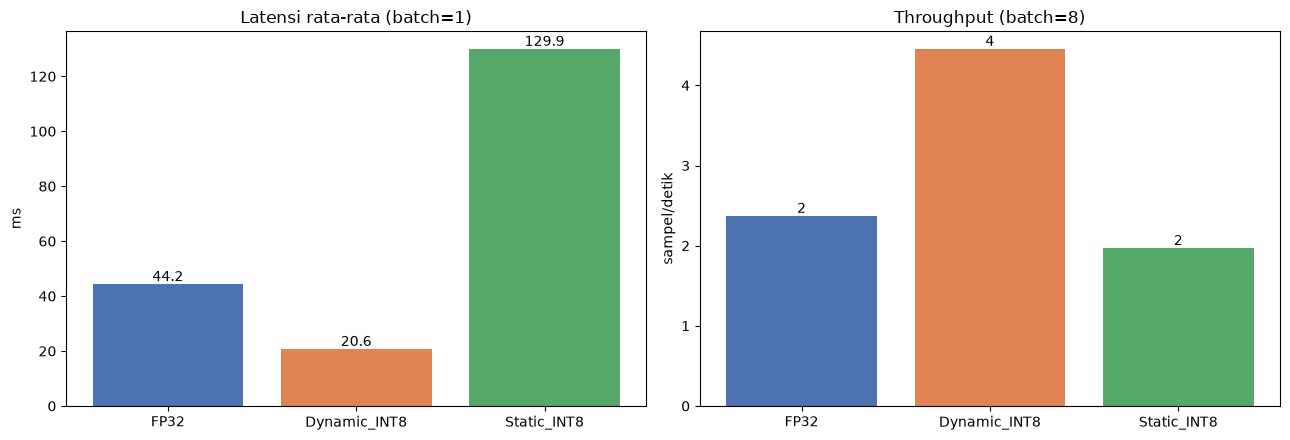

In [22]:
latency_b1 = latency_df[latency_df["batch_size"] == 1]
max_bs = latency_df["batch_size"].max()
latency_bmax = latency_df[latency_df["batch_size"] == max_bs]
colors = ["#4C72B0", "#DD8452", "#55A868"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].bar(latency_b1["Model"], latency_b1["mean_ms"], color=colors[:len(latency_b1)])
axes[0].set_title("Latensi rata-rata (batch=1)")
axes[0].set_ylabel("ms")
for i, v in enumerate(latency_b1["mean_ms"]):
    axes[0].text(i, v, f"{v:.1f}", ha="center", va="bottom")

axes[1].bar(latency_bmax["Model"], latency_bmax["throughput_samples_per_sec"], color=colors[:len(latency_bmax)])
axes[1].set_title(f"Throughput (batch={int(max_bs)})")
axes[1].set_ylabel("sampel/detik")
for i, v in enumerate(latency_bmax["throughput_samples_per_sec"]):
    axes[1].text(i, v, f"{v:.0f}", ha="center", va="bottom")

plt.tight_layout()
plt.show()


## 5. Interpretasi SHAP — Pengaruh Kuantisasi terhadap Explainability

In [23]:
assert cfg.SHAP_SUMMARY_CSV.exists(), (
    f"'{cfg.SHAP_SUMMARY_CSV}' belum ada. Jalankan 'python shap_analysis.py' dulu."
)

sim_df = pd.read_csv(cfg.SHAP_SIMILARITY_CSV)
summary_df = pd.read_csv(cfg.SHAP_SUMMARY_CSV, index_col=0)

print(f"Jumlah sampel yang dijelaskan dengan SHAP: {len(sim_df)}")
print("\nRata-rata & std kemiripan SHAP terhadap model FP32:")
summary_df


Jumlah sampel yang dijelaskan dengan SHAP: 12

Rata-rata & std kemiripan SHAP terhadap model FP32:


,mean,std
cosine_fp32_vs_dynamic,0.6645,0.2444
cosine_fp32_vs_static,0.1360,0.1826
pearson_fp32_vs_dynamic,0.6598,0.2497
pearson_fp32_vs_static,0.1314,0.1769
spearman_fp32_vs_dynamic,0.6583,0.1182
spearman_fp32_vs_static,0.0754,0.1128
jaccard_top5_fp32_vs_dynamic,0.4104,0.3285
jaccard_top5_fp32_vs_static,0.0959,0.1424


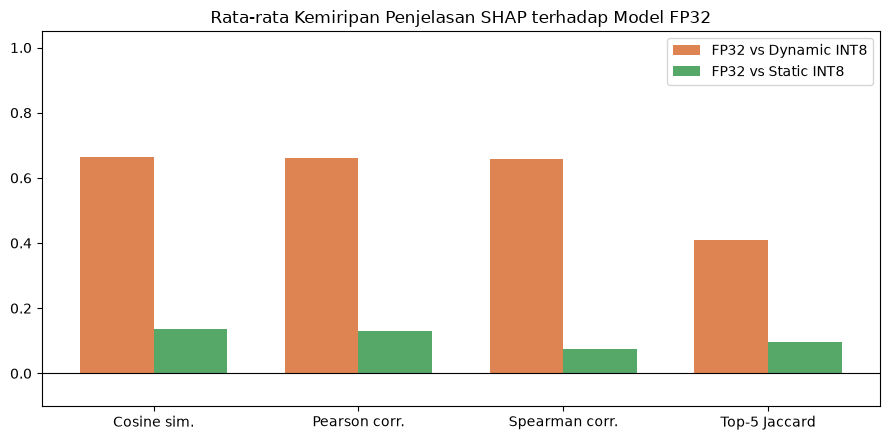

In [24]:
pairs = ["cosine", "pearson", "spearman", "jaccard_top5"]
labels_plot = ["Cosine sim.", "Pearson corr.", "Spearman corr.", "Top-5 Jaccard"]
dynamic_means = [sim_df[f"{p}_fp32_vs_dynamic"].mean() for p in pairs]
static_means = [sim_df[f"{p}_fp32_vs_static"].mean() for p in pairs]

x = np.arange(len(pairs))
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(x - 0.18, dynamic_means, 0.36, label="FP32 vs Dynamic INT8", color="#DD8452")
ax.bar(x + 0.18, static_means, 0.36, label="FP32 vs Static INT8", color="#55A868")
ax.set_xticks(x); ax.set_xticklabels(labels_plot)
ax.set_ylim(-0.1, 1.05); ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Rata-rata Kemiripan Penjelasan SHAP terhadap Model FP32")
ax.legend()
plt.tight_layout()
plt.show()


In [25]:
with open(cfg.SHAP_TOKENS_PKL, "rb") as f:
    token_level = pickle.load(f)

# Contoh detail token-level SHAP (1 sampel) — untuk lampiran laporan
ex = token_level[0]
print(f"Teks               : {ex['text']}")
print(f"Label asli         : {ex['true_label']}")
print(f"Kelas dijelaskan   : {ex['explained_class']}")

pd.DataFrame({
    "token": ex["tokens"],
    "shap_fp32": ex["shap_fp32"],
    "shap_dynamic": ex["shap_dynamic"],
    "shap_static": ex["shap_static"],
})


Teks               : 𝙃𝙖𝙥𝙥𝙮 𝙁𝙖𝙢𝙞𝙡𝙮 💕💕💕 Pasangan artis Vincent Zhao & istrinya Zhang Dan Lu bersama putra mereka.♥♥♥ Vincent Zhao Aktor kungfu yang menggantikan Jet Li sebagai tokoh guru wong Fei hung di film Once A Upon A Time in China tahun 1993
Label asli         : non_toxic
Kelas dijelaskan   : non_toxic


,token,shap_fp32,shap_dynamic,shap_static
0,𝙃,0.000365,0.001161,-0.001418
1,𝙃,0.000365,0.000445,0.000115
2,𝙖,0.000250,0.000233,0.003413
3,𝙥,0.000250,0.000494,-0.009876
4,𝙥,0.000254,0.000766,-0.002374
...,...,...,...,...
73,,0.000774,0.001513,-0.003379
74,1,-0.000345,-0.001935,0.015178
75,9,-0.000650,-0.001619,0.016691
76,9,-0.001129,-0.001453,-0.004120


Plot *global feature importance* (PNG) dan visualisasi highlight token interaktif (HTML) untuk
setiap model tersimpan di `artifacts/shap/plots/` dan `artifacts/shap/html/` — buka langsung file-nya
(HTML bisa dibuka di browser) untuk dilampirkan ke laporan.


## 6. Coba Prediksi Teks Baru (opsional, ringan — 1x forward pass ONNX)

In [35]:
from transformers import AutoTokenizer
import numpy as np

_tokenizer = AutoTokenizer.from_pretrained(str(cfg.ONNX_DIR))

MODEL_CHOICES = {
    "FP32": cfg.ONNX_FP32_PATH,
    "Dynamic INT8": cfg.ONNX_DYNAMIC_PATH,
    "Static INT8": cfg.ONNX_STATIC_PATH,
}

# Input teks
text = input("Masukkan kalimat yang ingin dites:\n> ").strip()

# Header output
print("\n" + "=" * 70)
print("HASIL PREDIKSI")
print("=" * 70)

# Tampilkan teks yang diuji
print("\nTeks yang diuji:")
print(f'"{text}"')

print("\n" + "-" * 70)

# Prediksi dengan setiap model
for model_name, model_path in MODEL_CHOICES.items():

    if not model_path.exists():
        print(f"\n[{model_name}] Model belum tersedia.")
        continue

    proba = ou.predict_proba(
        [text],
        model_path,
        _tokenizer
    )[0]

    cls = int(np.argmax(proba))
    label = cfg.LABEL_NAMES[cls]

    print(f"\nModel       : {model_name}")
    print(f"Prediksi    : {label}")
    print(f"Probabilitas: {float(proba[cls]):.4f}")

    print("Probabilitas kelas:")
    for i, prob in enumerate(proba):
        print(
            f"  {cfg.LABEL_NAMES[i]:<10}: {float(prob):.4f}"
        )

print("\n" + "=" * 70)


HASIL PREDIKSI

Teks yang diuji:
"brengsek sialan"

----------------------------------------------------------------------

Model       : FP32
Prediksi    : toxic
Probabilitas: 0.6579
Probabilitas kelas:
  non_toxic : 0.3421
  toxic     : 0.6579

Model       : Dynamic INT8
Prediksi    : non_toxic
Probabilitas: 0.9408
Probabilitas kelas:
  non_toxic : 0.9408
  toxic     : 0.0592

Model       : Static INT8
Prediksi    : non_toxic
Probabilitas: 1.0000
Probabilitas kelas:
  non_toxic : 1.0000
  toxic     : 0.0000



## 7. Diskusi & Kesimpulan

Isi bagian ini dengan interpretasi dari angka-angka di atas. Beberapa pertanyaan pemandu:

- **Trade-off ukuran vs performa**: berapa persen ukuran model berkurang untuk Dynamic vs Static, dan
  seberapa besar penurunan F1/accuracy masing-masing dibanding FP32?
- **Konsistensi explainability**: apakah nilai cosine/Pearson/Spearman mendekati 1 (interpretasi
  konsisten) atau jauh di bawahnya (kuantisasi mengubah pola token penting)? Apakah Static lebih
  terpengaruh dibanding Dynamic — sesuai dugaan awal karena Static mengkuantisasi aktivasi juga?
- **Rekomendasi**: kalau harus deploy dengan keterbatasan resource, kuantisasi mana yang paling masuk
  akal mengingat trade-off performa **dan** explainability di atas?
- **Keterbatasan**: ukuran sampel SHAP (`N_SHAP_SAMPLES` di `config.py`), ketimpangan kelas pada
  dataset, cakupan hanya pada label toksisitas (belum polarisasi).
- **Penelitian lanjutan**: kuantisasi INT4/mixed-precision, metode XAI lain (LIME, attention
  rollout) sebagai pembanding, atau quantization-aware training (QAT) sebagai alternatif PTQ.
